<a href="https://colab.research.google.com/github/yashu-32778/Medical-Diagnosis-Classification-Data-Preprocessing-and-Exploratory-Data-Analysis/blob/main/EDA%20internal%20lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/medical_diagnosis_classification.csv')
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             245 non-null    float64
 4   blood_pressure  246 non-null    object 
 5   cholesterol     234 non-null    float64
 6   smoker          248 non-null    object 
 7   bmi             239 non-null    float64
 8   patient_id      243 non-null    object 
 9   disease         237 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.8+ KB
None
  blood_sugar  bmi_dup sex   age blood_pressure  cholesterol smoker   bmi  \
0        High      NaN   M  89.0          109.9        203.0     No   NaN   
1          Lw     29.0   F  88.0          118.7        165.9     NO  29.0   
2        HIGH     19.2   M  80.0          107.5        166.8    Ye


**checking the missing values**

In [ ]:
df.isnull().sum()

,0
blood_sugar,24
bmi_dup,26
sex,19
age,20
blood_pressure,19
cholesterol,31
smoker,17
bmi,26
patient_id,22
disease,28


Remove the Duplicates

In [ ]:
df.drop_duplicates(inplace=True)
df

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
245,Low,17.3,F,NaN,97.9,203.7,No,17.3,P40245,0.0
246,NORMAL,30.5,M,78.0,97.6,218.7,N,30.5,P40246,0.0
247,Low,19.1,F,80.0,130.9,248.4,o,19.1,P40247,0.0
248,Hih,16.9,M,NaN,107.7,229.2,No,16.9,P40248,1.0


Replace the unknown values as Nan values

In [ ]:
df['blood_pressure']=df['blood_pressure'].replace('unknown',np.nan)
df

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,NaN,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
245,Low,17.3,F,NaN,97.9,203.7,No,17.3,P40245,0.0
246,NORMAL,30.5,M,78.0,97.6,218.7,N,30.5,P40246,0.0
247,Low,19.1,F,80.0,130.9,248.4,o,19.1,P40247,0.0
248,Hih,16.9,M,NaN,107.7,229.2,No,16.9,P40248,1.0


Convert blood pressure into numeric format

In [ ]:
df['blood_pressure'] = pd.to_numeric(df['blood_pressure'], errors='coerce')

Combine duplicate BMI cloumns

In [ ]:
# Already completed and dropped in the main pipeline cell above
#df["bmi"] = df["bmi"].fillna(df["bmi_dup"])

Remove unnecessary duplicate BMI Column

In [ ]:
# Already completed and dropped in the main pipeline cell above
df = df.drop(columns=["bmi_dup"], errors='ignore')

Standardize blood sugar values

In [ ]:
df["blood_sugar"] = df["blood_sugar"].str.strip().str.lower()

In [ ]:
df["blood_sugar"] = df["blood_sugar"].replace({
    "high": "High",
    "hig": "High",
    "hih": "High",
    "igh": "High",
    "hgh": "High",
    "low": "Low",
    "lw": "Low",
    "ow": "Low",
    "lo": "Low",
    "normal": "Normal",
    "norml": "Normal",
    "ormal": "Normal",
    "nomal": "Normal",
    "noral": "Normal",
    "norma": "Normal",
    "nrmal": "Normal"
})


Standardize smoker values

In [ ]:
df["smoker"] = df["smoker"].str.strip().str.lower()
df["smoker"] = df["smoker"].replace({
    "yes": "Yes",
    "ys": "Yes",
    "ye": "Yes",
    "no": "No",
    "n": "No",
    "o": "No"
})

 Fill missing numerical values with median

In [ ]:
numeric_cols = [
    "age",
    "blood_pressure",
    "cholesterol",
    "bmi"
]
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

Fill missing categorical values with mode

In [ ]:
categorical_cols = [
    "blood_sugar",
    "sex",
    "smoker"
]
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

Remove records with missing target values

In [ ]:
df = df.dropna(subset=["disease"])

Remove records with missing patient IDs

In [ ]:
df = df.dropna(subset=["patient_id"])

Filter invaild values

In [ ]:
df = df[
    (df["age"].between(0, 120)) &
    (df["bmi"].between(10, 80)) &
    (df["blood_pressure"].between(40, 250)) &
    (df["cholesterol"].between(50, 500))
]

filter vaild categorical values

In [ ]:
df = df[
    df["sex"].isin(["M", "F"]) &
    df["blood_sugar"].isin(["High", "Low", "Normal"]) &
    df["smoker"].isin(["Yes", "No"])
]

Convert disease into integer format

In [ ]:
df["disease"] = df["disease"].astype(int)

Display cleaned dataset

In [ ]:
print("\nCleaned Dataset:")
print(df.head())


Cleaned Dataset:
  blood_sugar sex   age  blood_pressure  cholesterol smoker   bmi patient_id  \
0        High   M  89.0           109.9        203.0     No  26.3     P40000   
2        High   M  80.0           107.5        166.8    Yes  19.2     P40002   
3        High   M  52.0           121.3        204.7     No  22.0     P40003   
4      Normal   M  36.0           118.2        202.7    Yes  28.0     P40004   
7         Low   M  80.0           122.5        170.4     No  17.2     P40007   

   disease  
0        1  
2        0  
3        0  
4        0  
7        0  


final missing values

In [ ]:
print(df.isnull().sum())
print("\nfinal data set shape:",df.shape)

blood_sugar       0
sex               0
age               0
blood_pressure    0
cholesterol       0
smoker            0
bmi               0
patient_id        0
disease           0
dtype: int64

final data set shape: (202, 9)


Data information about cleaned dataset

In [ ]:
print("First Five Records:")
print(df.head())
print("\nDataset Information:")
print(df.info())
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())

First Five Records:
  blood_sugar  bmi_dup sex   age blood_pressure  cholesterol smoker   bmi  \
0        High      NaN   M  89.0          109.9        203.0     No   NaN   
1          Lw     29.0   F  88.0          118.7        165.9     NO  29.0   
2        HIGH     19.2   M  80.0          107.5        166.8    Yes  19.2   
3        High     22.0   M   NaN          121.3        204.7      N  22.0   
4      NORMAL     28.0   M  36.0        unknown        202.7    Yes  28.0   

  patient_id  disease  
0     P40000      1.0  
1        NaN      0.0  
2     P40002      0.0  
3     P40003      0.0  
4     P40004      0.0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             

**Univariate**

1	Age Distribution

2	Disease Classification

3	Blood Sugar Distribution

4	BMI Distribution

5	Cholesterol Distribution

6	Smoking Status

7	Blood Pressure Distribution

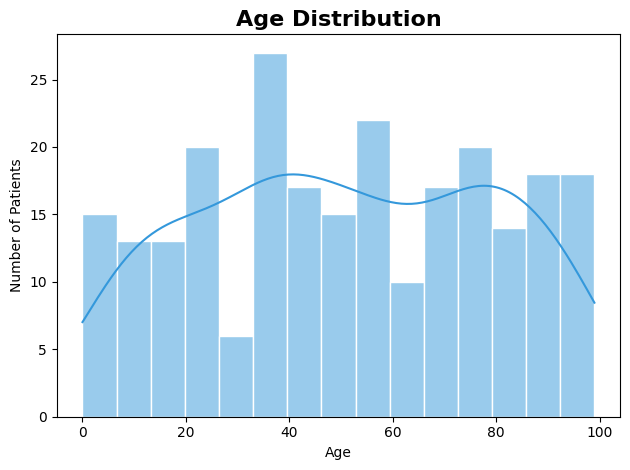

In [ ]:
plt.figure()
sns.histplot(data=df,x="age",bins=15,kde=True,color="#3498DB",edgecolor="white")
plt.title("Age Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

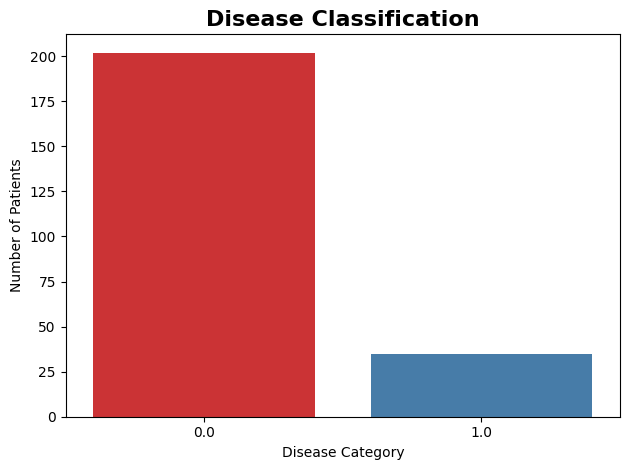

In [ ]:
plt.figure()
sns.countplot(data=df,x="disease",hue="disease",palette="Set1",legend=False)
plt.title("Disease Classification", fontsize=16, fontweight="bold")
plt.xlabel("Disease Category")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

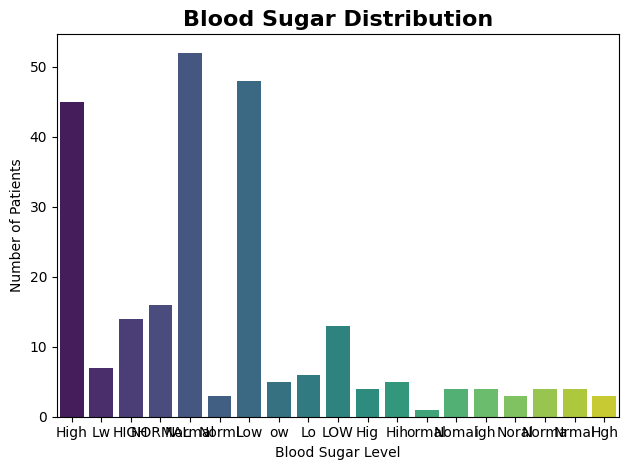

In [ ]:
plt.figure()
sns.countplot(data=df,x="blood_sugar",hue="blood_sugar",palette="viridis",legend=False)
plt.title("Blood Sugar Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Blood Sugar Level")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


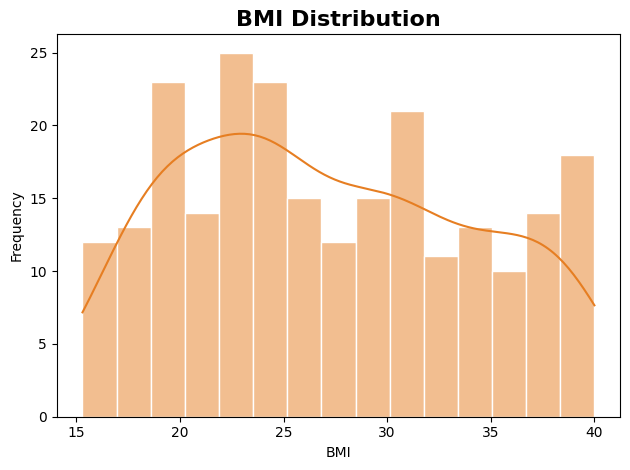

In [ ]:
plt.figure()
sns.histplot(data=df,x="bmi",bins=15,kde=True,color="#E67E22",edgecolor="white")
plt.title("BMI Distribution", fontsize=16, fontweight="bold")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

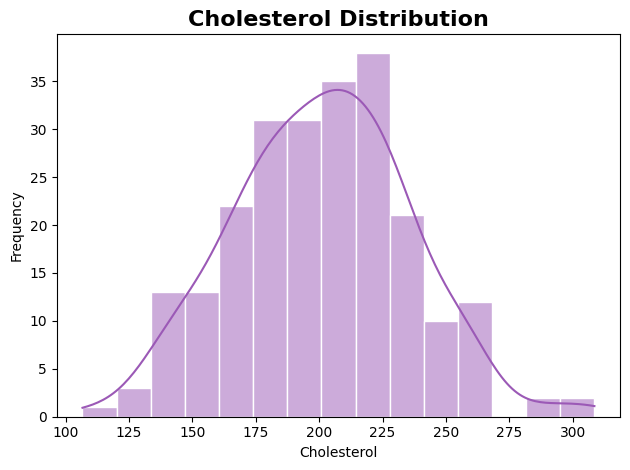

In [ ]:
plt.figure()
sns.histplot(data=df,x="cholesterol",bins=15,kde=True,color="#9B59B6",edgecolor="white")
plt.title("Cholesterol Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

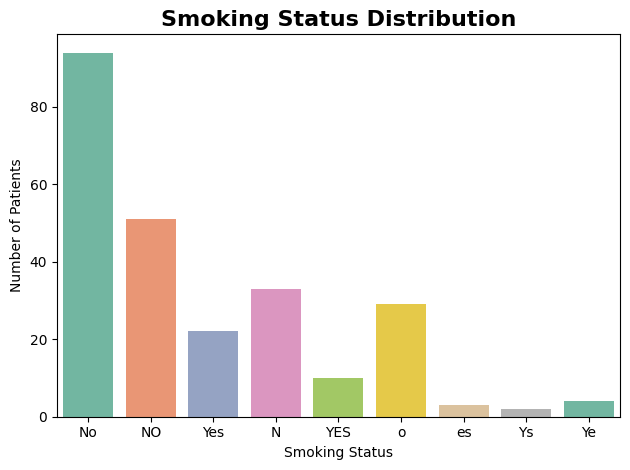

In [ ]:
plt.figure()
sns.countplot(data=df,x="smoker",hue="smoker",palette="Set2",legend=False)
plt.title("Smoking Status Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


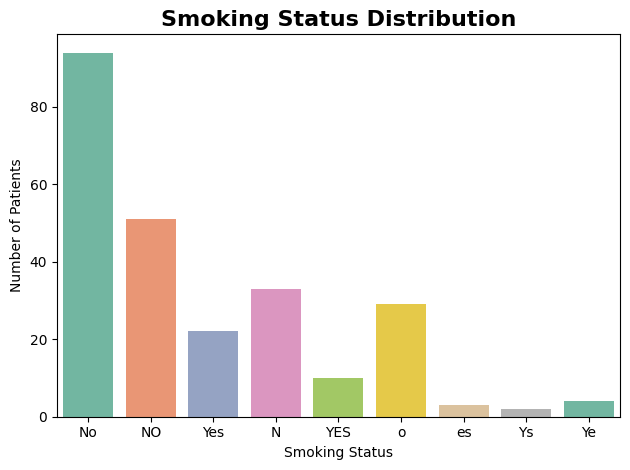

In [ ]:
plt.figure()
sns.countplot(data=df,x="smoker",hue="smoker",palette="Set2",legend=False)
plt.title("Smoking Status Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

**Multivariate**

8.Correlation Heatmap

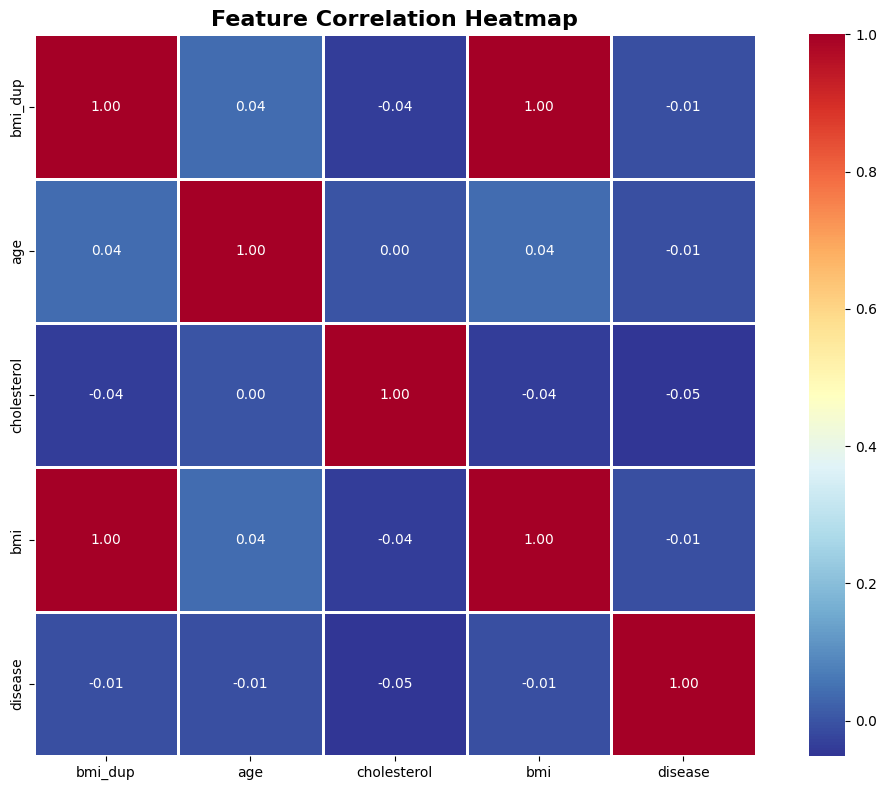

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(),annot=True,cmap="RdYlBu_r",linewidths=1,fmt=".2f",square=True)
plt.title("Feature Correlation Heatmap", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

**Bivariate**

9.Age vs BMI

10.Cholesterol vs Disease

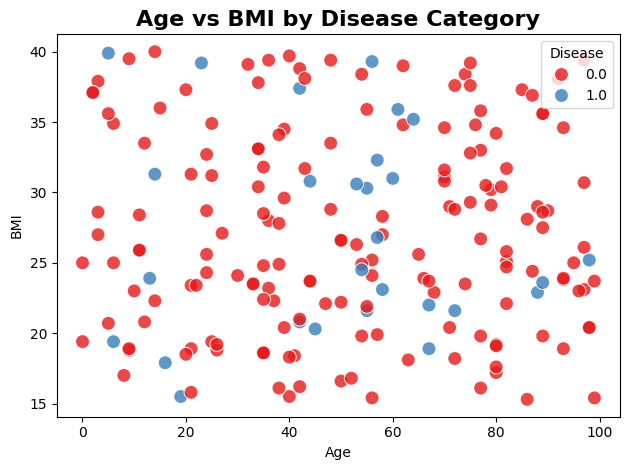

In [ ]:
plt.figure()
sns.scatterplot(data=df,x="age",y="bmi",hue="disease",palette="Set1",s=100,alpha=0.8)
plt.title("Age vs BMI by Disease Category", fontsize=16, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("BMI")
plt.legend(title="Disease")
plt.tight_layout()
plt.show()

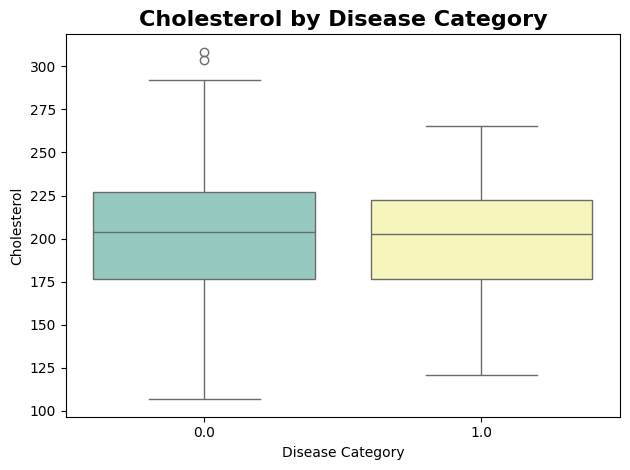

In [ ]:
plt.figure()
sns.boxplot(data=df,x="disease",y="cholesterol",hue="disease",palette="Set3",legend=False)
plt.title("Cholesterol by Disease Category", fontsize=16, fontweight="bold")
plt.xlabel("Disease Category")
plt.ylabel("Cholesterol")
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("final_dataset.csv")